In [21]:
import pandas as pd
import numpy as np

df = pd.read_csv('cause_death.csv')
df.head()

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...


In [22]:
df.dtypes

Cause              object
Type               object
Year                int64
Data Redundancy     int64
Total Deaths        int64
Source             object
Page at Source     object
Source URL         object
dtype: object

In [23]:
df.fillna(0)
df.drop_duplicates()

q1 = df["Total Deaths"].quantile(0.25)
q3 = df["Total Deaths"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr 
upper = q3 + 1.5 * iqr 

df_clean = df[(df["Total Deaths"] >= lower) & (df["Total Deaths"] <= upper)]

print(f"Data sebelum cleaning : {len(df)}")
print(f"Data sesudah cleaning : {len(df_clean)}")

Data sebelum cleaning : 680
Data sesudah cleaning : 552


In [24]:
# 1. Uji Shapiro-Wilk untuk normalitas

from scipy import stats

shapiro_test = stats.shapiro(df_clean['Total Deaths'])
print("Hasil Uji Shapiro-Wilk")
print("Statistik : ", shapiro_test.statistic)
print("P-Value : ", shapiro_test.pvalue)

Hasil Uji Shapiro-Wilk
Statistik :  0.5902771802575988
P-Value :  4.714403494882831e-34


In [25]:
# 2. Korelasi Pearson

from scipy import stats

correlation, p_value = stats.pearsonr(df_clean["Year"], df_clean["Total Deaths"])

print(f"Korelasi antara Year dan Total Deaths: {correlation}")
print(f"P-value: {p_value}")


Korelasi antara Year dan Total Deaths: -0.10708174138273542
P-value: 0.011822788193798232


In [26]:
df_clean["Year"].sort_values()

1      2000
641    2000
39     2000
393    2000
360    2001
       ... 
87     2021
609    2021
634    2021
22     2021
679    2021
Name: Year, Length: 552, dtype: int64

In [27]:
# 2. Korelasi Spearman

from scipy import stats

df_group = df_clean.groupby("Year")["Total Deaths"].sum()

spearman_year = stats.spearmanr(df_group.index, df_group.values)
print(f"Korelasi antara Year dan Total Deaths : ")
print(f"Statistik : {spearman_year.statistic}")
print(f"P-value: {spearman_year.pvalue}")


Korelasi antara Year dan Total Deaths : 
Statistik : 0.12140033879164315
P-value: 0.5904546067875798


In [28]:
from scipy.stats import kendalltau

# Korelasi Kendall Tau
kendall_year = kendalltau(df_group.index, df_group.values)
print(f"Korelasi antara Year dan Total Deaths : ")
print(f"Statistik : {kendall_year.statistic}")
print(f"P-value: {kendall_year.pvalue}")


Korelasi antara Year dan Total Deaths : 
Statistik : 0.10822510822510822
P-value: 0.5030535233842987


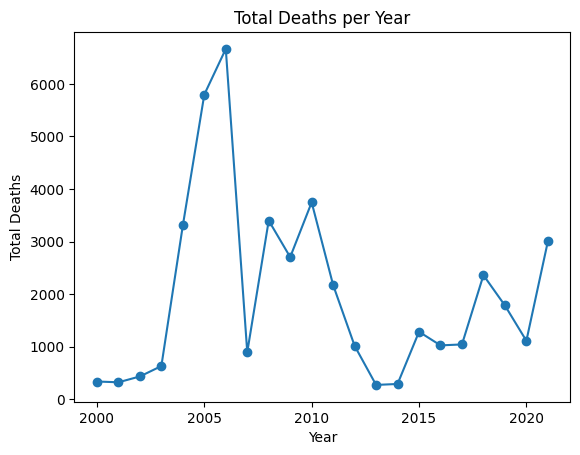

In [29]:
import matplotlib.pyplot as plt

# Plot Total Deaths per Year
plt.plot(df_group.index, df_group.values, marker='o')
plt.xlabel("Year")
plt.ylabel("Total Deaths")
plt.title("Total Deaths per Year")
plt.show()


assignment

In [30]:
df = pd.read_csv("penyakit_jantung.csv")
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,female,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,female,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,male,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,female,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,male,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,male,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,female,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,female,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,female,0,130,131,0,1,115,1,1.2,1,1,3,0


In [31]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    object 
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(12), object(1)
memory usage: 33.3+ KB


In [33]:
# df["Date_reported"] = pd.to_datetime(df["Date_reported"])
# df["Year"] = df["Date_reported"].dt.year
# df

In [34]:
q1 = df["trestbps"].quantile(0.25)
q3 = df["trestbps"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr 
upper = q3 + 1.5 * iqr 

df_clean = df[(df["trestbps"] >= lower) & (df["trestbps"] <= upper)]

In [35]:
group_tres = df_clean.groupby(["age"])["trestbps"].sum().reset_index()

# group_case = df_clean.groupby(["Date_reported", "Year"])["New_cases"].sum().reset_index()
# date = group_case.index.get_level_values("Date_reported")

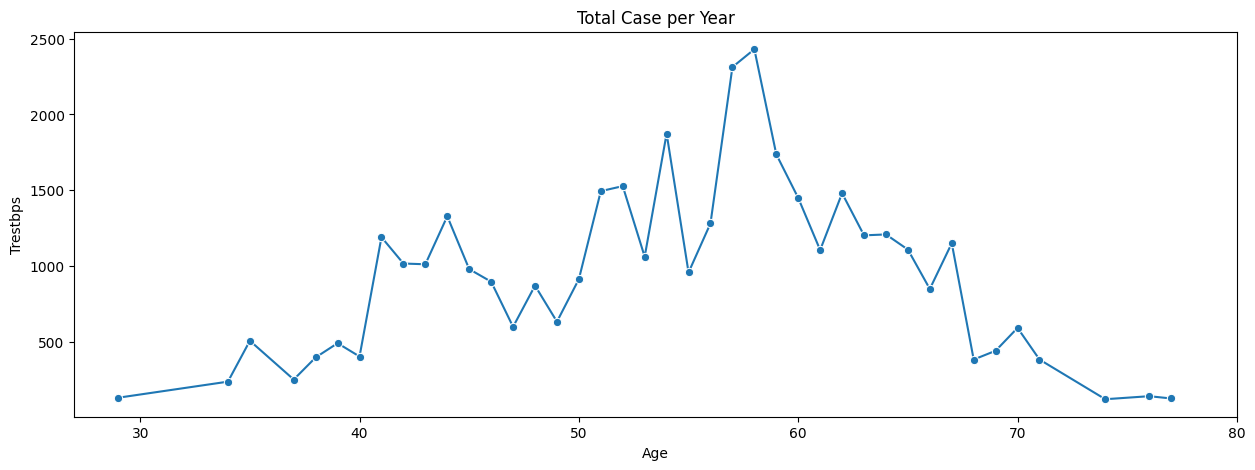

In [36]:
# Plot trestbps per age

import seaborn as sns

plt.figure(figsize=(15,5))
sns.lineplot(x = "age", y = "trestbps", data = group_tres, marker="o")
plt.xlim([27,80])
plt.xlabel("Age")
plt.ylabel("Trestbps")
plt.title("Total Case per Year")
plt.show()

In [37]:
shapiro_tres = stats.shapiro(df_clean["trestbps"])
shapiro_tres

ShapiroResult(statistic=0.9846882038549042, pvalue=0.0031591560976713664)

In [38]:
print("Hasil Uji Shapiro-Wilk")
print("Statistik : ", shapiro_tres.statistic)
print("P-Value : ", shapiro_tres.pvalue)

Hasil Uji Shapiro-Wilk
Statistik :  0.9846882038549042
P-Value :  0.0031591560976713664


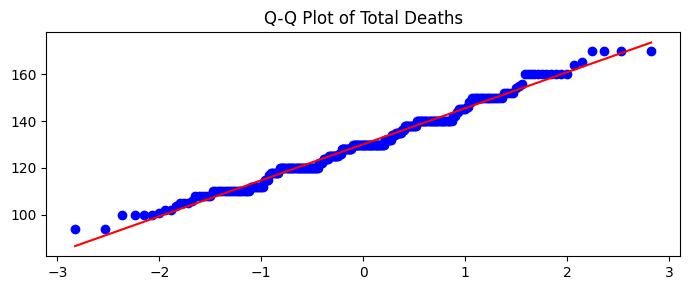

In [39]:
from scipy.stats import probplot
import matplotlib.pyplot as plt

# Q-Q Plot
plt.figure(figsize=(7, 3))
probplot(df_clean["trestbps"], dist="norm", plot=plt)
plt.title('Q-Q Plot of Total Deaths')  # Sesuaikan judul jika perlu
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [40]:
spearman_tres = stats.spearmanr(group_tres["age"], group_tres["trestbps"])

In [41]:
print(f"Korelasi antara age dan trestbps : ")
print(f"Statistik : {spearman_tres.statistic}")
print(f"P-value: {spearman_tres.pvalue}")

Korelasi antara age dan trestbps : 
Statistik : 0.05096040773160039
P-value: 0.751683453432509


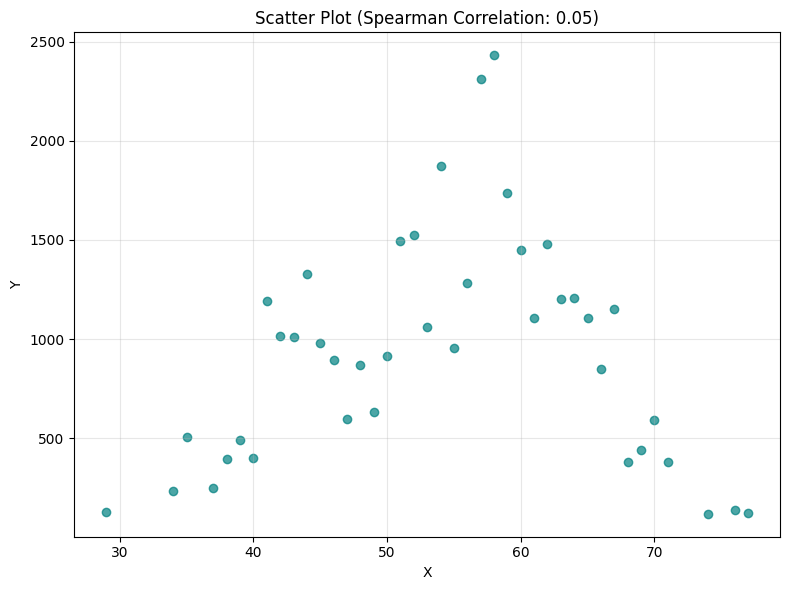

In [42]:
plt.figure(figsize=(8, 6))
plt.scatter(group_tres["age"], group_tres["trestbps"], alpha=0.7, color='teal')
plt.title(f'Scatter Plot (Spearman Correlation: {spearman_tres.statistic:.2f})')
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()